# 3D. LSTM Autoencoder - NASA Turbofan Engines
Train AE on first-20%-of-cycles (healthy) sensor data.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import MinMaxScaler

In [2]:
df = pd.read_csv("../datasets/AutoEncoder/NASA Turbofan ENgine/NASA TurboFan Engine.csv")

df["max_cycle"] = df.groupby("unit")["cycle"].transform("max")
df["healthy"] = df["cycle"] <= df["max_cycle"] * 0.2

feat_cols = [c for c in df.columns if c.startswith("sensor") or c.startswith("setting")]
x = df[feat_cols].to_numpy().astype("float32")

scaler = MinMaxScaler()
x = scaler.fit_transform(x)
y = (~df["healthy"]).astype(int).to_numpy()

# sliding windows (W=15)
W = 15
Xw = []
yw = []
for i in range(len(x) - W + 1):
    Xw.append(x[i:i+W])
    yw.append(y[i:i+W].max())
Xw = np.array(Xw)
yw = np.array(yw)

Xw_norm = Xw[yw == 0]
print("windows:", Xw.shape, "healthy:", Xw_norm.shape)

windows: (20617, 15, 24) healthy: (2686, 15, 24)


In [3]:
model = keras.Sequential([
    layers.Input(shape=(15, Xw.shape[2])),
    layers.LSTM(32, activation="relu"),
    layers.RepeatVector(15),
    layers.LSTM(32, activation="relu", return_sequences=True),
    layers.TimeDistributed(layers.Dense(Xw.shape[2])),
])
model.compile(optimizer="adam", loss="mse")
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         7,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector (RepeatVector)    │ (None, 15, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 15, 32)         │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 15, 24)         │           792 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,408 (64.09 KB)

 Trainable params: 16,408 (64.09 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
history = model.fit(Xw_norm, Xw_norm, epochs=5, validation_split=0.1)

Epoch 1/5
76/76 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0735 - val_loss: 0.0128
Epoch 2/5
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0100 - val_loss: 0.0078
Epoch 3/5
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0079 - val_loss: 0.0074
Epoch 4/5
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0076 - val_loss: 0.0073
Epoch 5/5
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0075 - val_loss: 0.0072


In [5]:
recon = model.predict(Xw)
err = np.mean((Xw - recon) ** 2, axis=(1, 2))

threshold = np.quantile(err[yw == 0], 0.95)
y_pred = (err > threshold).astype(int)

print(f"flagged faulty: {y_pred.sum()}  actual non-healthy: {yw.sum()}")
print(f"threshold: {threshold:.6f}")

flagged faulty: 4079  actual non-healthy: 17931
threshold: 0.013123


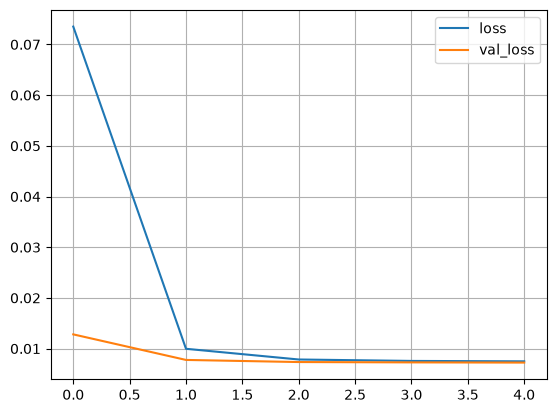

In [6]:
for k, v in history.history.items():
    plt.plot(v, label=k)
plt.legend()
plt.grid()
plt.show()